# 02 - Tabular baselines

How far can simple per-user features go, with no graph? Every model is scored on the **same** repeated, stratified 5x5 cross-validation folds over users, with fixed hyperparameters (nothing is tuned on test folds). These numbers are the bar the GNN has to beat.

- **Feature set A:** the five engineered counts (`n_logon`, `n_after_hours`, `n_pcs`, `n_device`, `n_file`).
- **Feature set B:** A plus `active_days` (distinct days with a logon) and each count divided by `active_days`.
- **Models:** constant prior, one-feature `n_device` rules, logistic regression, random forest, XGBoost.

In [1]:
%load_ext autoreload
%autoreload 2

import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import mannwhitneyu
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import precision_recall_curve, average_precision_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler
from xgboost import XGBClassifier

from itgnn.data import load_config, prepare
from itgnn.evaluation import make_folds, evaluate_scores, summarize
from itgnn.graph import user_features, user_features_extended, FEATURE_COLS, FEATURE_COLS_B

# Run from the repo root so the relative paths in the config and prepare() resolve.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
cfg = load_config("configs/config.yaml")
SEED, K, TOP_FRAC = cfg["seed"], 20, 0.10
sns.set_theme(style="whitegrid", context="notebook")
pd.options.display.float_format = "{:,.3f}".format

d = prepare(cfg)
users, labels = d["users"], d["labels"]
folds = make_folds(users, labels, cfg["cv"]["n_splits"], cfg["cv"]["n_repeats"], SEED)
XA = user_features(d["logon"], d["device"], d["file"], users)
XB = user_features_extended(d["logon"], d["device"], d["file"], users)
y = pd.Series([int(u in labels) for u in users], index=users)
prevalence = y.mean()
print(f"{len(users)} users, {y.sum()} malicious ({prevalence:.1%}); {len(folds)} folds; "
      f"test fold size {len(folds[0]['test'])}, malicious per test fold {y[folds[0]['test']].sum()}")
print("feature set A:", XA.shape[1], "columns | feature set B:", XB.shape[1], "columns")

1000 users, 70 malicious (7.0%); 25 folds; test fold size 200, malicious per test fold 14
feature set A: 5 columns | feature set B: 11 columns


## 1. Models and cross-validation

Every model gets only the training users of a fold and scores the held-out users. Hyperparameters are fixed in one place (below). Logistic regression uses `log1p` and standardization (fit on the training fold); the forest and XGBoost handle the heavy tails themselves. Class imbalance is handled with `balanced` class weights (logistic regression, forest) or `scale_pos_weight` computed from each training fold (XGBoost). The constant prior and the `n_device` rules do not depend on the feature set (`n_device` is in both A and B), so they run once and are labeled "A/B".

With about 14 malicious users in a 200-user test fold, precision@20 can be at most 0.7, so recall@20 is the more informative of the two.

In [2]:
def lr():
    return make_pipeline(FunctionTransformer(np.log1p), StandardScaler(),
                         LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000))

def rf():
    return RandomForestClassifier(n_estimators=300, min_samples_leaf=3, class_weight="balanced_subsample",
                                  n_jobs=-1, random_state=SEED)

def xgb(ytr):
    return XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1,
                         scale_pos_weight=(ytr == 0).sum() / (ytr == 1).sum(),
                         n_jobs=4, random_state=SEED, verbosity=0)

def fit_score(model, Xtr, ytr, Xte):
    return model.fit(Xtr, ytr).predict_proba(Xte)[:, 1]

# (name, feature set label, feature matrix or None, scoring function(Xtr, ytr, Xte) -> scores)
SPECS = [
    ("constant prior",      "A/B", XA, lambda Xtr, ytr, Xte: np.full(len(Xte), ytr.mean())),
    ("n_device score",      "A/B", XA, lambda Xtr, ytr, Xte: Xte["n_device"].to_numpy(float)),
    ("n_device > 0",        "A/B", XA, lambda Xtr, ytr, Xte: (Xte["n_device"] > 0).to_numpy(float)),
] + [
    (name, fs, X, fn)
    for fs, X in [("A", XA), ("B", XB)]
    for name, fn in [
        ("logistic regression", lambda Xtr, ytr, Xte: fit_score(lr(), Xtr, ytr, Xte)),
        ("random forest",       lambda Xtr, ytr, Xte: fit_score(rf(), Xtr, ytr, Xte)),
        ("xgboost",             lambda Xtr, ytr, Xte: fit_score(xgb(ytr), Xtr, ytr, Xte)),
    ]
]
mid = lambda name, fs: name if fs == "A/B" else f"{name} ({fs})"

metric_rows, oof_rows, rf_B = [], [], {}
for f in folds:
    tr, te = f["train"], f["test"]
    ytr, yte = y[tr], y[te]
    for name, fs, X, fn in SPECS:
        s = fn(X.loc[tr], ytr, X.loc[te])
        metric_rows.append({"model": mid(name, fs), "repeat": f["repeat"], "fold": f["fold"],
                            **evaluate_scores(yte.to_numpy(), s, K)})
        oof_rows.append(pd.DataFrame({"user": te, "repeat": f["repeat"], "model": name,
                                      "feature_set": fs, "score": s, "label": yte.to_numpy()}))
    if f["repeat"] == 0:  # keep fitted forests (feature set B) for permutation importance
        rf_B[f["fold"]] = rf().fit(XB.loc[tr], ytr)
results = pd.DataFrame(metric_rows)
oof = pd.concat(oof_rows, ignore_index=True)
oof["mid"] = [mid(n, fs) for n, fs in zip(oof["model"], oof["feature_set"])]
Path("results").mkdir(exist_ok=True)
oof.drop(columns="mid").to_csv("results/baseline_oof_scores.csv", index=False)
print("saved results/baseline_oof_scores.csv:", oof.shape)
ORDER = [mid(n, fs) for n, fs, _, _ in SPECS]

saved results/baseline_oof_scores.csv: (45000, 7)


## 2. Results table

Mean ± standard deviation over the 25 folds. PR-AUC is the headline metric; the constant prior sets the floor (PR-AUC equals the prevalence, ROC-AUC 0.5). Precision@k and recall@k use k=20 and are tie-aware.

In [3]:
S = summarize(results)
tbl = pd.DataFrame({m: S[m].apply(lambda r: f"{r['mean']:.3f} ± {r['std']:.3f}", axis=1)
                    for m in ["pr_auc", "roc_auc", "precision_at_k", "recall_at_k"]}).loc[ORDER]
tbl.columns = ["PR-AUC", "ROC-AUC", f"precision@{K}", f"recall@{K}"]
display(tbl)
print(f"prevalence (PR-AUC floor): {prevalence:.3f}")

,PR-AUC,ROC-AUC,precision@20,recall@20
model,,,,
constant prior,0.070 ± 0.000,0.500 ± 0.000,0.070 ± 0.000,0.100 ± 0.000
n_device score,0.198 ± 0.026,0.845 ± 0.027,0.138 ± 0.089,0.197 ± 0.128
n_device > 0,0.266 ± 0.025,0.895 ± 0.013,0.266 ± 0.025,0.381 ± 0.035
logistic regression (A),0.415 ± 0.090,0.937 ± 0.019,0.428 ± 0.088,0.611 ± 0.126
random forest (A),0.982 ± 0.021,0.998 ± 0.002,0.694 ± 0.022,0.991 ± 0.031
xgboost (A),0.987 ± 0.019,0.999 ± 0.002,0.698 ± 0.010,0.997 ± 0.014
logistic regression (B),0.589 ± 0.106,0.963 ± 0.012,0.544 ± 0.058,0.777 ± 0.083
random forest (B),0.995 ± 0.011,1.000 ± 0.001,0.700 ± 0.000,1.000 ± 0.000
xgboost (B),0.985 ± 0.024,0.998 ± 0.003,0.694 ± 0.017,0.991 ± 0.024


prevalence (PR-AUC floor): 0.070


## 3. PR-AUC per fold

Each dot is one of the 25 test folds. The spread shows how much a single split can mislead; the black bar is the mean.

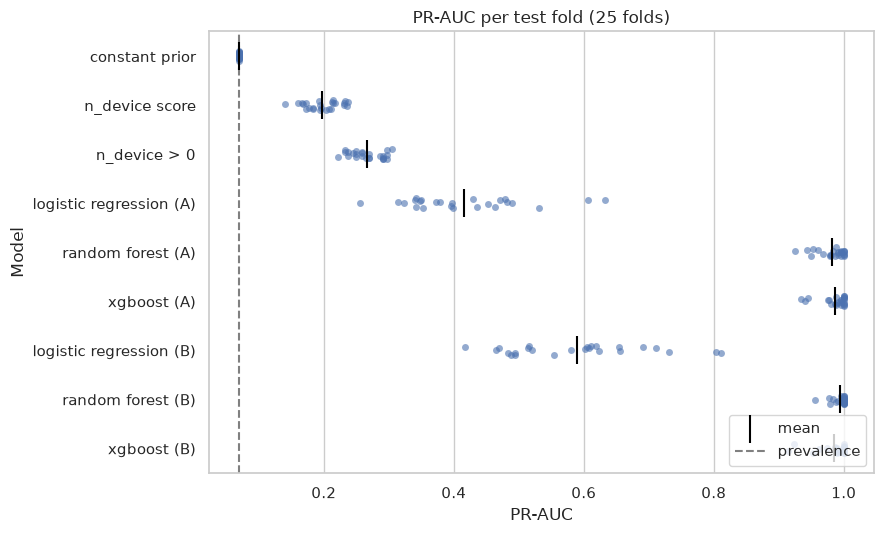

In [4]:
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.stripplot(data=results, y="model", x="pr_auc", order=ORDER, orient="h", alpha=0.6, size=5, ax=ax)
means = results.groupby("model")["pr_auc"].mean().loc[ORDER]
ax.scatter(means.values, range(len(ORDER)), marker="|", s=400, color="black", zorder=3, label="mean")
ax.axvline(prevalence, color="gray", ls="--", label="prevalence")
ax.set(title="PR-AUC per test fold (25 folds)", xlabel="PR-AUC", ylabel="Model")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 4. Paired differences

Because every model uses the same folds, we can compare models fold by fold. Each row is the PR-AUC difference on the same test fold (mean ± std over the 25 folds, plus the share of folds where the first model wins). **Caveat:** repeated-CV folds share training data and the same users reappear in every repeat, so the folds are not independent. The std understates the real uncertainty, and this is descriptive evidence only, not a significance test.

In [5]:
pv = results.pivot_table(index=["repeat", "fold"], columns="model", values="pr_auc")
pairs = [("random forest (B)", "random forest (A)"),
         ("random forest (A)", "n_device score"),
         ("xgboost (A)", "random forest (A)")]
rows = {}
for a, b in pairs:
    dlt = pv[a] - pv[b]
    rows[f"{a} - {b}"] = {"mean diff": dlt.mean(), "std": dlt.std(), "folds where first wins": f"{(dlt > 0).mean():.0%}"}
display(pd.DataFrame(rows).T)

,mean diff,std,folds where first wins
random forest (B) - random forest (A),0.013,0.016,84%
random forest (A) - n_device score,0.784,0.033,100%
xgboost (A) - random forest (A),0.005,0.019,72%


## 5. Pooled out-of-fold PR curves

Within one repeat every user is scored exactly once (by a model that never saw them), so the 25 folds of a repeat can be pooled into one curve over all users. Thick lines are repeat 0, thin lines the other four repeats. The dashed line is the prevalence: a model with no skill sits there.

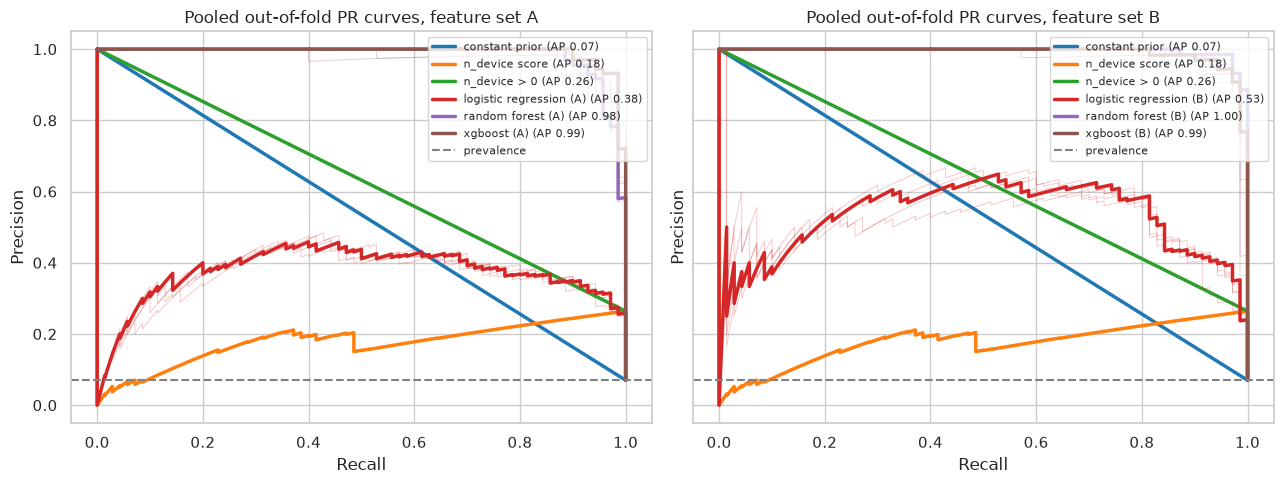

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
colors = dict(zip(["constant prior", "n_device score", "n_device > 0", "logistic regression", "random forest", "xgboost"],
                  sns.color_palette("tab10", 6)))
for ax, fs in zip(axes, ["A", "B"]):
    for name in colors:
        m = mid(name, "A/B" if name in ("constant prior", "n_device score", "n_device > 0") else fs)
        for r in sorted(oof["repeat"].unique()):
            sub = oof[(oof["mid"] == m) & (oof["repeat"] == r)]
            p, rc, _ = precision_recall_curve(sub["label"], sub["score"])
            lab = f"{m} (AP {average_precision_score(sub['label'], sub['score']):.2f})" if r == 0 else None
            ax.plot(rc, p, color=colors[name], lw=2.5 if r == 0 else 0.7, alpha=1 if r == 0 else 0.25, label=lab)
    ax.axhline(prevalence, color="gray", ls="--", label="prevalence")
    ax.set(title=f"Pooled out-of-fold PR curves, feature set {fs}", xlabel="Recall", ylabel="Precision")
    ax.legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

## 6. Flagging the top 10% of users

A practical question: if an analyst reviews only the 10% of users with the highest score, what do they get? In each test fold we flag the top 10% by score (ties broken at random with a fixed seed). The reference model is the random forest on feature set A. As an optional second row we also show the model with the best mean PR-AUC; that choice was **selected on the same data** it is evaluated on, so it is slightly optimistic. Counts are for repeat 0, where each user appears once.

best by mean CV PR-AUC: random forest (B) (0.995) | reference: random forest (A) (0.982)
random forest (A) -> flagged 100 users, caught 69 of 70 insiders
random forest (B) -> flagged 100 users, caught 70 of 70 insiders


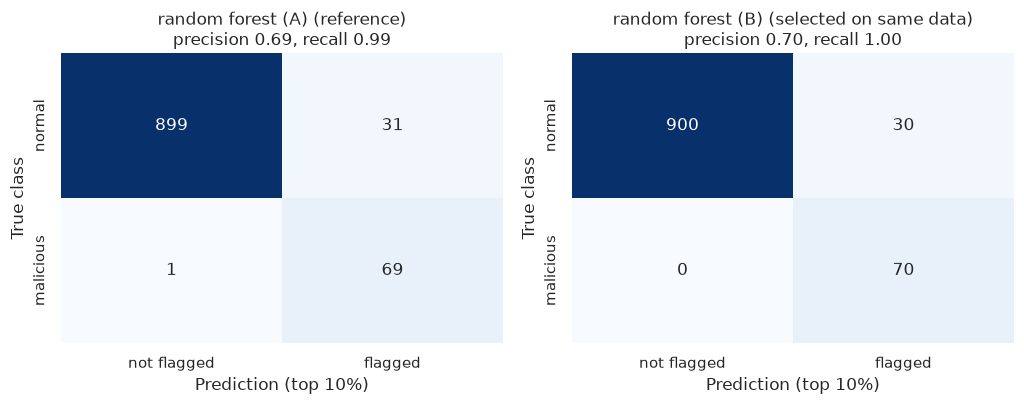

In [7]:
rng = np.random.default_rng(SEED)

def flags(model_id, repeat):
    """Binary top-10% flag per user, chosen within each test fold."""
    sub = oof[(oof["mid"] == model_id) & (oof["repeat"] == repeat)].copy()
    fold_of = {u: f["fold"] for f in folds if f["repeat"] == repeat for u in f["test"]}
    sub["fold"] = sub["user"].map(fold_of)
    sub["flag"] = False
    for _, g in sub.groupby("fold"):
        order = g.index.to_numpy()[np.lexsort((rng.random(len(g)), -g["score"].to_numpy()))]
        sub.loc[order[: int(np.ceil(TOP_FRAC * len(g)))], "flag"] = True
    return sub

REF = "random forest (A)"
cands = results.groupby("model")["pr_auc"].mean().drop(["constant prior"]).sort_values(ascending=False)
BEST = cands.index[0]
models_shown = [REF] + ([BEST] if BEST != REF else [])
print("best by mean CV PR-AUC:", BEST, f"({cands.iloc[0]:.3f})", "| reference:", REF, f"({cands[REF]:.3f})")
fig, axes = plt.subplots(1, len(models_shown), figsize=(5.2 * len(models_shown), 4.2), squeeze=False)
for ax, m in zip(axes[0], models_shown):
    g = flags(m, 0)
    cm = pd.crosstab(g["label"].map({0: "normal", 1: "malicious"}), g["flag"].map({False: "not flagged", True: "flagged"}))
    cm = cm.reindex(index=["normal", "malicious"], columns=["not flagged", "flagged"]).fillna(0).astype(int)
    tp, fp = cm.loc["malicious", "flagged"], cm.loc["normal", "flagged"]
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax)
    note = " (selected on same data)" if m == BEST and m != REF else " (reference)"
    ax.set(title=f"{m}{note}\nprecision {tp/(tp+fp):.2f}, recall {tp/y.sum():.2f}", xlabel="Prediction (top 10%)", ylabel="True class")
    print(m, "-> flagged", int(tp + fp), "users, caught", int(tp), "of", int(y.sum()), "insiders")
plt.tight_layout(); plt.show()

## 7. Permutation importance (random forest, feature set B)

For each held-out fold of repeat 0 we shuffle one feature at a time and measure the drop in average precision. Large drop = the model relied on it. **Caveat:** many features here are strongly correlated (a count and its per-day rate, `n_device` and `n_file`), so permuting one leaves its twin to compensate and **correlated features share credit**: each can look less important than the pair really is. Read the ranking of groups, not single bars.

,mean,std over folds
active_days,0.342,0.060
n_file_per_day,0.013,0.008
n_device,0.009,0.015
n_device_per_day,0.009,0.014
n_pcs_per_day,0.003,0.006
n_file,0.001,0.002
n_pcs,0.000,0.000
n_after_hours_per_day,0.000,0.000
n_after_hours,0.000,0.000
n_logon,0.000,0.003


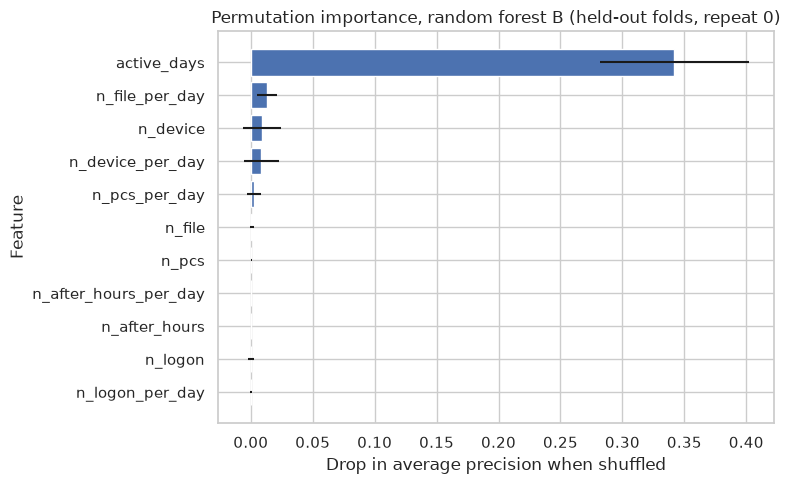

In [8]:
imps = []
for fo, model in rf_B.items():
    te = folds[fo]["test"]  # repeat 0 folds come first, so index == fold number
    pi = permutation_importance(model, XB.loc[te], y[te], scoring="average_precision",
                                n_repeats=10, random_state=SEED, n_jobs=1)
    imps.append(pd.Series(pi.importances_mean, index=XB.columns))
imps = pd.DataFrame(imps)
pim = pd.DataFrame({"mean": imps.mean(), "std over folds": imps.std()}).sort_values("mean", ascending=False)
display(pim)
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(pim.index[::-1], pim["mean"][::-1], xerr=pim["std over folds"][::-1], color="#4c72b0")
ax.set(title="Permutation importance, random forest B (held-out folds, repeat 0)",
       xlabel="Drop in average precision when shuffled", ylabel="Feature")
plt.tight_layout(); plt.show()

## 8. Tenure hypothesis: active days by class

Hypothesis: malicious users have a different tenure, i.e. a different number of active days, for example because insiders leave the company shortly after an attack. If so, `active_days` carries information about the outcome itself. We compare the two classes and test `active_days` as a one-feature score.

,count,mean,std,min,25%,50%,75%,max
class,,,,,,,,
malicious,70.000,220.571,57.357,113.000,171.250,213.000,262.750,335.000
normal,930.000,338.525,62.549,25.000,346.000,346.000,346.000,495.000


Mann-Whitney U p = 9.4e-54; AUC of active_days alone (higher = malicious) = 0.053


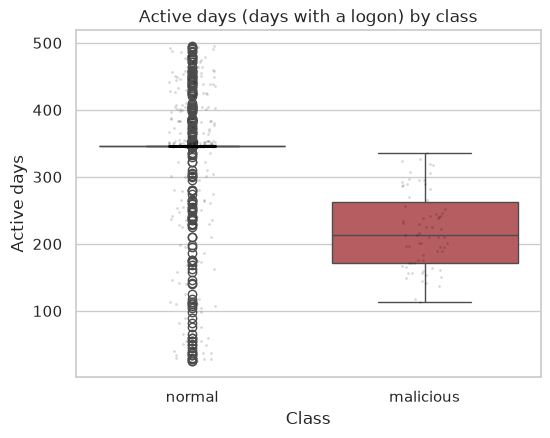

most common active_days value: 346
share of users with active_days == 346: normal 75.5%, malicious 0.0%
share of users with n_logon == 346 (most common): normal 48.4%, malicious 0.0%


In [9]:
ad = XB["active_days"]
dfc = pd.DataFrame({"active_days": ad, "class": y.map({0: "normal", 1: "malicious"})})
display(dfc.groupby("class")["active_days"].describe())
u, p = mannwhitneyu(ad[y == 1], ad[y == 0])
auc = u / ((y == 1).sum() * (y == 0).sum())
print(f"Mann-Whitney U p = {p:.2g}; AUC of active_days alone (higher = malicious) = {auc:.3f}")
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.boxplot(data=dfc, x="class", y="active_days", order=["normal", "malicious"], hue="class",
            palette={"normal": "#4c72b0", "malicious": "#c44e52"}, legend=False, ax=ax)
sns.stripplot(data=dfc, x="class", y="active_days", order=["normal", "malicious"], color="black", alpha=0.15, size=2, ax=ax)
ax.set(title="Active days (days with a logon) by class", xlabel="Class", ylabel="Active days")
plt.show()
# How much of the signal is simply "was present for the whole period"?
full = ad.mode()[0]
print(f"most common active_days value: {full}")
print(f"share of users with active_days == {full}: normal {(ad[y == 0] == full).mean():.1%}, malicious {(ad[y == 1] == full).mean():.1%}")
m_log = XA["n_logon"].mode()[0]
print(f"share of users with n_logon == {m_log} (most common): normal {(XA['n_logon'][y == 0] == m_log).mean():.1%}, malicious {(XA['n_logon'][y == 1] == m_log).mean():.1%}")

## 9. Recall by insider scenario

CERT insiders follow different scenarios (1: after-hours logons, removable drive and uploads to wikileaks; 2: job-hunting and a thumb drive; 3: disgruntled administrator). Using the same top-10% flags as section 6, which scenarios does the model catch? Recall is shown for repeat 0 and averaged over all repeats. Scenario 3 has only 10 users, so its numbers are coarse.

In [10]:
ins = pd.read_csv("data/raw/answers/insiders.csv")
ins = ins[ins["dataset"].astype(str) == "4.2"].set_index("user")["scenario"]
rows = []
for m in models_shown:
    per_rep = []
    for r in sorted(oof["repeat"].unique()):
        g = flags(m, r)
        g = g[g["label"] == 1].assign(scenario=lambda x: x["user"].map(ins))
        per_rep.append(g.groupby("scenario")["flag"].mean())
    per_rep = pd.DataFrame(per_rep).reset_index(drop=True)
    for sc in [1, 2, 3]:
        rows.append({"model": m, "scenario": sc, "insiders": int((ins == sc).sum()),
                     "recall (repeat 0)": per_rep.loc[0, sc], "recall (mean of repeats)": per_rep[sc].mean()})
display(pd.DataFrame(rows).set_index(["model", "scenario"]))

insiders  recall (repeat 0)  \
model             scenario                                
random forest (A) 1               30              1.000   
                  2               30              0.967   
                  3               10              1.000   
random forest (B) 1               30              1.000   
                  2               30              1.000   
                  3               10              1.000   

                            recall (mean of repeats)  
model             scenario                            
random forest (A) 1                            1.000  
                  2                            0.980  
                  3                            1.000  
random forest (B) 1                            1.000  
                  2                            1.000  
                  3                            1.000

## Key takeaways

- **Floor and ceiling.** The constant prior scores PR-AUC 0.070 (the prevalence). `n_device > 0` alone reaches 0.266 (ROC-AUC 0.895), the raw `n_device` score 0.198. Logistic regression gets 0.415 (A) and 0.589 (B). Tree models are far higher: random forest 0.982 (A) and 0.995 (B), XGBoost 0.987 (A) and 0.985 (B), with recall@20 of 0.99-1.00 (precision@20 caps near 0.70 with about 14 insiders per test fold).
- **Linear vs trees.** The gap between logistic regression (0.42-0.59) and the forests (0.98-0.995) means the signal is not monotone in the counts: the trees find thresholds or ranges that a standardized `log1p` linear model cannot.
- **Feature set B adds little.** RF-B minus RF-A is +0.013 PR-AUC (84% of folds), XGBoost-A minus RF-A is +0.005 (72%), and both are within one fold-std. Repeated-CV folds are correlated, so these gaps are descriptive, not significant. B helps logistic regression more (0.415 to 0.589) because `active_days` is a clean linear signal.
- **Top-10% flags.** Reviewing the top 10% of users (100 per repeat) catches 69 of 70 insiders with RF-A and 70 of 70 with RF-B (selected on the same data, so optimistic). All three scenarios are caught: RF-A recall is 1.00 / 0.97 / 1.00 for scenarios 1 / 2 / 3 on repeat 0 (1.00 / 0.98 / 1.00 averaged over repeats). Scenario 3 has only 10 users.
- **Tenure dominates, and this is a warning.** `active_days` carries most of the permutation importance in RF-B (0.342 against at most 0.013 for any other feature). 75.5% of normal users have active_days = 346 (the whole period) and 0% of insiders do (median 213 vs 346). 48.4% of normal users have exactly n_logon = 346 and no insider does. The AUC of `active_days` alone is 0.053, so shorter tenure alone is a near-perfect indicator of being an insider. Insiders leave the company soon after the attack, so presence over the period leaks the outcome.
- **The leakage is not limited to `active_days`.** All features are computed over the full period, including after the attacks, so tenure is baked into every count (`n_logon`, `n_file` and so on grow with time present) and the per-day rates. RF-A's 0.98 should not be read as detection skill: it most likely comes largely from tenure encoded in A's counts. These scores are an upper bound and are not what an analyst would have in real time. The planned weekly-window features, built only from activity before a cutoff, are the fix, and this baseline is the number to compare them with.
- **Correlated features share credit** in permutation importance, so the small values for the other features say little about how useful they are on their own.